# 06 · Pythonic Techniques

The patterns that distinguish fluent Python: iterators and generators, decorators, context managers,
functional tools, type hints, logging, automated tests and concurrency. Each one appears constantly in
libraries you will use and in code reviews.

**You will learn**
1. Iterators and generators, and the `itertools` toolbox
2. Decorators: timing, caching, retrying
3. Context managers: guaranteed cleanup with `with`
4. Functional tools: `functools.partial`, `reduce`, `map`/`filter`
5. Type hints that tools can check
6. Logging instead of `print`
7. Testing with `pytest`
8. Concurrency: threads, processes and `asyncio`, and which one fits which problem (measured)

## 1. Iterators, generators and `itertools`
Anything you can loop over is an *iterable*; `iter()` gives an *iterator* that hands out items one at a
time. Generators are the easy way to write iterators, and `itertools` combines them without building
lists in memory.

In [1]:
import itertools as it

nums = iter([10, 20, 30])
print(next(nums), next(nums), list(nums))

def read_in_batches(items, size):
    batch = []
    for item in items:
        batch.append(item)
        if len(batch) == size:
            yield batch
            batch = []
    if batch:
        yield batch

print(list(read_in_batches(range(7), 3)))
print(list(it.islice(it.count(start=1, step=3), 5)))                 # infinite counter, first 5
print(list(it.accumulate([1, 2, 3, 4])))                              # running total
print(list(it.chain("ab", "cd")), list(it.product("ab", repeat=2)))
print({k: list(g) for k, g in it.groupby(sorted("mississippi"))})

10 20 [30]
[[0, 1, 2], [3, 4, 5], [6]]
[1, 4, 7, 10, 13]
[1, 3, 6, 10]
['a', 'b', 'c', 'd'] [('a', 'a'), ('a', 'b'), ('b', 'a'), ('b', 'b')]
{'i': ['i', 'i', 'i', 'i'], 'm': ['m'], 'p': ['p', 'p'], 's': ['s', 's', 's', 's']}


## 2. Decorators
A decorator is a function that takes a function and returns a new one with extra behaviour. `@timer`
above a definition means `f = timer(f)`.

In [2]:
import functools, time

def timer(func):
    @functools.wraps(func)                  # keep the original name and docstring
    def wrapper(*args, **kwargs):
        t0 = time.perf_counter()
        result = func(*args, **kwargs)
        print(f"{func.__name__} took {(time.perf_counter() - t0) * 1000:.1f} ms")
        return result
    return wrapper

def retry(times: int, exceptions=(Exception,)):
    '''A decorator with arguments: a function that returns a decorator.'''
    def decorate(func):
        @functools.wraps(func)
        def wrapper(*args, **kwargs):
            for attempt in range(1, times + 1):
                try:
                    return func(*args, **kwargs)
                except exceptions as e:
                    print(f"attempt {attempt} failed: {e}")
            raise RuntimeError(f"{func.__name__} failed {times} times")
        return wrapper
    return decorate

@timer
def slow_sum(n): return sum(range(n))

calls = {"n": 0}
@retry(times=3, exceptions=(ConnectionError,))
def flaky():
    calls["n"] += 1
    if calls["n"] < 3:
        raise ConnectionError("network blip")
    return "ok"

print(slow_sum(5_000_000), flaky())

slow_sum took 159.7 ms
attempt 1 failed: network blip
attempt 2 failed: network blip
12499997500000 ok


In [3]:
@functools.lru_cache(maxsize=None)          # memoisation from the standard library
def fib(n): return n if n < 2 else fib(n - 1) + fib(n - 2)

t0 = time.perf_counter(); print(fib(200)); print(f"{(time.perf_counter() - t0) * 1000:.2f} ms with caching")
print(fib.cache_info())

280571172992510140037611932413038677189525
0.53 ms with caching
CacheInfo(hits=198, misses=201, maxsize=None, currsize=201)


## 3. Context managers
`with` guarantees that setup is paired with cleanup, even when an exception is raised. Files, locks,
database transactions and temporary settings all use it.

In [4]:
from contextlib import contextmanager, suppress
import os, tempfile

@contextmanager
def working_directory(path):
    old = os.getcwd()
    os.chdir(path)
    try:
        yield path
    finally:
        os.chdir(old)                         # always runs

tmp = tempfile.mkdtemp()
with working_directory(tmp):
    with open("notes.txt", "w") as f:         # the file is closed when the block ends
        f.write("hello")
    print("inside:", os.getcwd() == os.path.realpath(tmp), os.listdir("."))
print("back to:", os.getcwd() != os.path.realpath(tmp))

with suppress(FileNotFoundError):             # ignore one specific, expected error
    os.remove("does-not-exist.txt")

class Timer:
    '''The class form: __enter__ and __exit__.'''
    def __enter__(self):
        self.t0 = time.perf_counter(); return self
    def __exit__(self, exc_type, exc, tb):
        self.elapsed = time.perf_counter() - self.t0
        return False                          # do not swallow exceptions

with Timer() as t:
    sum(i * i for i in range(1_000_000))
print(f"block took {t.elapsed * 1000:.1f} ms")

inside: True ['notes.txt']
back to: True
block took 132.5 ms


## 4. Functional tools

In [5]:
from functools import partial, reduce
from operator import mul, itemgetter

power = lambda base, exp: base ** exp
square, cube = partial(power, exp=2), partial(power, exp=3)
print(square(7), cube(3))

print(reduce(mul, range(1, 6)))                        # 5! = 120
orders = [("pen", 3), ("book", 12), ("bag", 25)]
print(sorted(orders, key=itemgetter(1), reverse=True))
print(list(filter(lambda o: o[1] > 5, orders)), [name for name, price in orders if price > 5])

49 27
120
[('bag', 25), ('book', 12), ('pen', 3)]
[('book', 12), ('bag', 25)] ['book', 'bag']


## 5. Type hints
Hints document intent and let tools (`mypy`, `pyright`, your editor) catch bugs before the code runs.

In [6]:
from typing import TypedDict, Literal, Callable, Iterable, TypeVar

T = TypeVar("T")

class User(TypedDict):
    name: str
    role: Literal["admin", "viewer"]

def first_match(items: Iterable[T], predicate: Callable[[T], bool]) -> T | None:
    return next((i for i in items if predicate(i)), None)

users: list[User] = [{"name": "ana", "role": "viewer"}, {"name": "ben", "role": "admin"}]
print(first_match(users, lambda u: u["role"] == "admin"))
print(first_match.__annotations__)

{'name': 'ben', 'role': 'admin'}
{'items': typing.Iterable[~T], 'predicate': typing.Callable[[~T], bool], 'return': typing.Optional[~T]}


## 6. Logging instead of print
`logging` adds levels, timestamps and destinations (console, file, a log service) that you can change
without touching the code.

In [7]:
import logging, io

stream = io.StringIO()
logging.basicConfig(stream=stream, level=logging.INFO, force=True,
                    format="%(asctime)s %(levelname)-7s %(name)s: %(message)s", datefmt="%H:%M:%S")
log = logging.getLogger("pipeline")

log.debug("not shown: below the INFO level")
log.info("loaded %d rows", 1200)              # arguments, not f-strings: formatted only if emitted
log.warning("3 rows had missing prices")
try:
    1 / 0
except ZeroDivisionError:
    log.exception("division failed")          # includes the traceback
print(stream.getvalue())

01:23:44 INFO    pipeline: loaded 1200 rows
01:23:44 WARNING pipeline: 3 rows had missing prices
01:23:44 ERROR   pipeline: division failed
Traceback (most recent call last):
  File "/tmp/ipykernel_821678/3560669218.py", line 12, in <module>
    1 / 0
    ~~^~~
ZeroDivisionError: division by zero



## 7. Testing with pytest
Tests are small functions whose names start with `test_`; `assert` is all you need. `pytest` finds and
runs them. Below, a tiny module and its tests are written to disk and run.

In [8]:
import subprocess, sys, textwrap
proj = tempfile.mkdtemp()
with open(os.path.join(proj, "pricing.py"), "w") as f:
    f.write(textwrap.dedent("""
        def apply_discount(price: float, percent: float) -> float:
            if not 0 <= percent <= 100:
                raise ValueError("percent must be between 0 and 100")
            return round(price * (1 - percent / 100), 2)
    """))
with open(os.path.join(proj, "test_pricing.py"), "w") as f:
    f.write(textwrap.dedent("""
        import pytest
        from pricing import apply_discount

        def test_basic():
            assert apply_discount(100, 20) == 80

        @pytest.mark.parametrize("price, pct, expected", [(50, 0, 50), (50, 100, 0), (19.99, 15, 16.99)])
        def test_many(price, pct, expected):
            assert apply_discount(price, pct) == expected

        def test_rejects_bad_percent():
            with pytest.raises(ValueError):
                apply_discount(10, 120)
    """))
r = subprocess.run([sys.executable, "-m", "pytest", "-q", proj], capture_output=True, text=True, cwd=proj)
print(r.stdout[-400:])

.....                                                                    [100%]
5 passed in 0.02s



## 8. Concurrency: threads, processes, asyncio
Python has a *global interpreter lock* (GIL): in the standard interpreter only one thread runs Python
bytecode at a time. The consequence:

- **I/O-bound** work (waiting for networks, disks, databases): threads or `asyncio` overlap the waiting.
- **CPU-bound** work (pure Python computation): only **processes** use several cores (or libraries like
  NumPy that release the GIL internally). Python 3.13 adds an optional free-threaded build that removes
  the GIL; it is still experimental.

Measured below with a simulated I/O task (sleeping) and a CPU task (counting primes):

In [9]:
import asyncio
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor

def io_task(_):
    time.sleep(0.2)                          # stands for waiting on a network request
    return 1

def cpu_task(n):
    return sum(1 for k in range(2, n) if all(k % d for d in range(2, int(k ** 0.5) + 1)))

def timed(label, fn):
    t0 = time.perf_counter(); fn(); dt = time.perf_counter() - t0
    print(f"{label:<34}{dt:6.2f} s"); return dt

JOBS, N = 8, 60_000
results = {}
results["I/O sequential"] = timed("I/O: sequential", lambda: [io_task(i) for i in range(JOBS)])
with ThreadPoolExecutor(8) as ex:
    results["I/O threads"] = timed("I/O: 8 threads", lambda: list(ex.map(io_task, range(JOBS))))

async def io_async(_):
    await asyncio.sleep(0.2)
async def main():
    await asyncio.gather(*(io_async(i) for i in range(JOBS)))
# notebooks already run an event loop, so run asyncio in a fresh thread for this demo
with ThreadPoolExecutor(1) as ex:
    results["I/O asyncio"] = timed("I/O: asyncio", lambda: ex.submit(asyncio.run, main()).result())

results["CPU sequential"] = timed("CPU: sequential", lambda: [cpu_task(N) for _ in range(4)])
with ThreadPoolExecutor(4) as ex:
    results["CPU threads"] = timed("CPU: 4 threads", lambda: list(ex.map(cpu_task, [N] * 4)))
# Worker processes must be able to find cpu_task. Functions defined in a notebook are only visible to
# them with the "fork" start method (Linux, Colab). In a .py script any start method works.
import multiprocessing as mp
ctx = mp.get_context("fork") if "fork" in mp.get_all_start_methods() else None
if ctx:
    with ProcessPoolExecutor(4, mp_context=ctx) as ex:
        results["CPU processes"] = timed("CPU: 4 processes", lambda: list(ex.map(cpu_task, [N] * 4)))
else:
    print("CPU: processes need a .py file on this platform (no 'fork'); see the exercise below")

I/O: sequential                     1.60 s


I/O: 8 threads                      0.20 s


I/O: asyncio                        0.20 s


CPU: sequential                     0.70 s


CPU: 4 threads                      0.90 s


CPU: 4 processes                    0.31 s


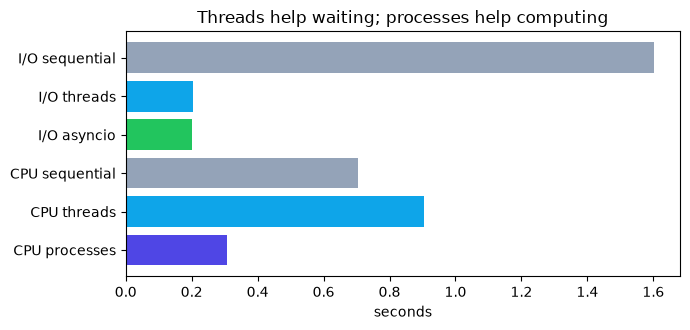

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 3.4))
colors = ["#94a3b8", "#0ea5e9", "#22c55e", "#94a3b8", "#0ea5e9", "#4f46e5"]
plt.barh(list(results), list(results.values()), color=colors); plt.gca().invert_yaxis()
plt.xlabel("seconds"); plt.title("Threads help waiting; processes help computing"); plt.tight_layout(); plt.show()

Threads and asyncio finish the I/O jobs in about the time of one job, because the waiting overlaps.
For the CPU jobs threads give no speed-up, often a small slow-down (the GIL plus switching overhead),
while processes run on separate cores and cut the time by more than half. The gain is below the ideal
4x because starting worker processes and sending work to them has a cost, which matters for jobs this short.

## Exercises
1. Write a decorator `@count_calls` that records how many times a function has been called.
2. Turn `Timer` into a decorator as well as a context manager (`contextlib.ContextDecorator`).
3. Add a test for `apply_discount` with a negative price and decide what the function should do.
4. Rewrite the CPU benchmark with NumPy (vectorised sieve) and compare it with four processes.